## Clustering: Densidad (DBSCAN y HDBSCAN)

- **Se ejecuta en local (scikit-learn)** sobre `local_*` (todas las entidades, muestra de proveedores): necesitan los
  vecinos de cada punto, costo ~O(n log n) a O(n²). Spark solo se usa para escribir resultados
- Qué buscan: grupos de **forma arbitraria** y, sobre todo, **ruido** (puntos en zonas de baja densidad = outliers)
- `eps` se elige con el gráfico de **k-distancia**; se barre una grilla eps × min_samples (insumo de la web interactiva)

### Imports

In [1]:
import os, socket, time, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, Window, functions as F

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_columns", 40)

### Utilidades

- Constantes

In [2]:
SECCION, NOTEBOOK = "02_Clustering", "c_densidad"

proyecto = Path.cwd()
while not (proyecto / "docker-compose.yml").exists() and proyecto != proyecto.parent:
    proyecto = proyecto.parent

final_dir = proyecto / "data" / "final"
artef_dir = proyecto / "data" / "artefactos"
clus_dir  = proyecto / "data" / "clustering"
clus_dir.mkdir(parents=True, exist_ok=True)
SUJETOS = {"entidad": "entidad_key", "proveedor": "proveedor_key"}
SEED = 42

out_dir = proyecto / SECCION / "temp" / NOTEBOOK
fig_dir, tab_dir, web_dir = out_dir / "figs", out_dir / "tablas", out_dir / "web"
for d in (fig_dir, tab_dir, web_dir):
    d.mkdir(parents=True, exist_ok=True)

def mostrar_fig(nombre):
    plt.tight_layout()
    plt.savefig(fig_dir / f"{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

def guardar_tabla(df, nombre):
    sdf = spark.createDataFrame(df) if isinstance(df, pd.DataFrame) else df
    sdf.coalesce(1).write.mode("overwrite").parquet(str(tab_dir / nombre))
    sdf.toPandas().to_json(web_dir / f"{nombre}.json", orient="records", force_ascii=False, date_format="iso", indent=1)
    return len(df) if isinstance(df, pd.DataFrame) else sdf.count()

def leer(directorio, nombre):
    return spark.read.parquet(str(directorio / nombre))

- Spark

In [3]:
spark_master = os.environ.get("spark_master", "local[*]")

builder = (SparkSession.builder
           .appName(NOTEBOOK)
           .master(spark_master)
           .config("spark.driver.memory",   os.environ.get("SPARK_DRIVER_MEMORY", "4g"))
           .config("spark.executor.memory", os.environ.get("SPARK_EXECUTOR_MEMORY", "4g"))
           .config("spark.sql.shuffle.partitions", "24")
           .config("spark.ui.showConsoleProgress", "false")
           .config("spark.sql.session.timeZone", "America/Lima")
           .config("spark.sql.execution.arrow.pyspark.enabled", "true"))

if spark_master.startswith("spark://"):
    builder = (builder.config("spark.driver.host", socket.gethostname())
                      .config("spark.driver.bindAddress", "0.0.0.0"))

spark = builder.getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

### Verificación del cluster

In [4]:
sc = spark.sparkContext
estado = sc._jsc.sc().getExecutorMemoryStatus()
print(f"Master        : {sc.master}")
print(f"Executors     : {estado.size() - 1}")
print(f"Cores totales : {sc.defaultParallelism}")
print(f"Memoria driver: {sc._jvm.java.lang.Runtime.getRuntime().maxMemory() / 1024**3:.1f} GB")
print("UI del job    : http://localhost:4040")

Master        : spark://spark-master:7077
Executors     : 0
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


### Carga

In [5]:
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
try:
    from sklearn.cluster import HDBSCAN
except ImportError:
    HDBSCAN = None
    print("aviso: scikit-learn < 1.3 sin HDBSCAN -> docker compose exec jupyter pip install -U scikit-learn")

config = json.loads((clus_dir / "config.json").read_text())
MIN_SAMPLES, QS, RUIDO_MAX = [5, 10, 20], [0.80, 0.90, 0.95, 0.98], 0.10
MIN_CLUSTER = [10, 25, 50]
N_SIL, N_WEB = 3000, 2000

def cargar(s):
    key = config[s]["key"]
    loc = pd.read_parquet(clus_dir / f"local_{s}")
    km = pd.read_parquet(clus_dir / f"kmeans_{s}")[[key, "cluster", "dist_centro"]].rename(columns={"cluster": "kmeans"})
    loc = loc.merge(km, on=key, how="left")
    X = loc[[f"pc_{i}" for i in range(config[s]["n_comp"])]].to_numpy()
    return loc, X

def silueta(X, lab):
    m = lab >= 0
    if len(set(lab[m])) < 2 or m.sum() < 10:
        return np.nan
    return float(silhouette_score(X[m], lab[m], sample_size=int(min(N_SIL, m.sum())), random_state=SEED))

def elegir(g, ruido_max):
    ok = g[(g.n_clusters >= 2) & (g.pct_ruido <= ruido_max)]
    ok = ok if len(ok) else g[g.n_clusters >= 2]
    return ok.sort_values("silhouette", ascending=False).iloc[0] if len(ok) else g.iloc[0]

datos = {s: cargar(s) for s in config}
for s, (loc, X) in datos.items():
    print(s, X.shape)

entidad (2695, 6)
proveedor (5865, 7)


In [6]:
def rasgos(z, cols, top=3, prefijo=""):
    # describe un punto o un clúster por sus features más alejadas de la media (en desviaciones estándar)
    z = z[cols].astype(float)
    orden = z.abs().sort_values(ascending=False).index[:top]
    return ", ".join(f"{c[len(prefijo):]} {'↑' if z[c] > 0 else '↓'}{abs(z[c]):.1f}σ" for c in orden)

---
### 1. Gráfico de k-distancia

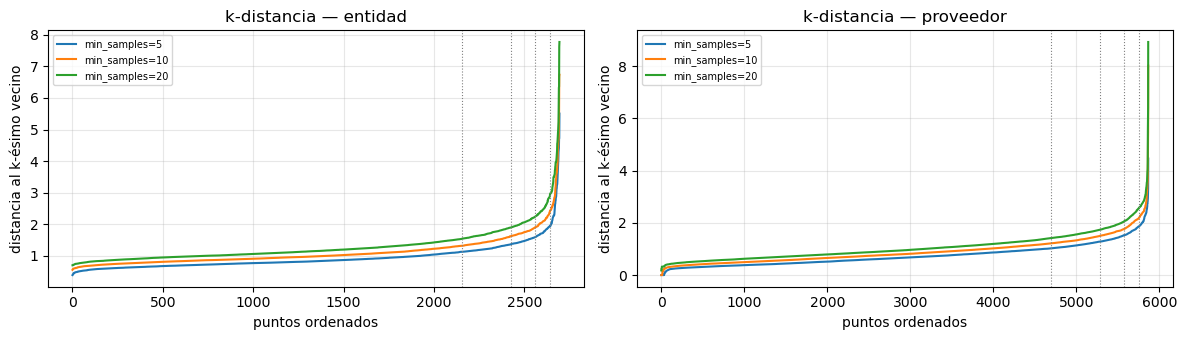

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
kdist = {}
for i, (s, (loc, X)) in enumerate(datos.items()):
    for ms in MIN_SAMPLES:
        kd = np.sort(NearestNeighbors(n_neighbors=ms).fit(X).kneighbors(X)[0][:, -1])
        kdist[(s, ms)] = kd
        ax[i].plot(kd, label=f"min_samples={ms}")
    for q in QS:
        ax[i].axvline(q * len(kd), color="grey", ls=":", lw=.8)
    ax[i].set_title(f"k-distancia — {s}"); ax[i].set_xlabel("puntos ordenados")
    ax[i].set_ylabel("distancia al k-ésimo vecino"); ax[i].legend(fontsize=7)
mostrar_fig("k_distancia")

- El "codo" de la curva separa puntos en zonas densas (izquierda) de puntos aislados (derecha). Las líneas grises son
  los cuantiles usados como `eps` candidatos (80–98%)

### 2. DBSCAN: grilla eps × min_samples

In [8]:
grid_db, etiquetas_db = [], {}
for s, (loc, X) in datos.items():
    for ms in MIN_SAMPLES:
        for q in QS:
            eps = float(np.quantile(kdist[(s, ms)], q))
            lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
            etiquetas_db[(s, ms, q)] = lab
            grid_db.append({"sujeto": s, "min_samples": ms, "q_eps": q, "eps": round(eps, 4),
                            "n_clusters": len(set(lab) - {-1}), "pct_ruido": round(float((lab == -1).mean()), 4),
                            "silhouette": silueta(X, lab)})
grid_db = pd.DataFrame(grid_db)
sel_db = {s: elegir(grid_db[grid_db.sujeto == s], RUIDO_MAX) for s in datos}
for s, r in sel_db.items():
    print(s, "->", dict(r))
grid_db

entidad -> {'sujeto': 'entidad', 'min_samples': 10, 'q_eps': 0.8, 'eps': 1.3173, 'n_clusters': 2, 'pct_ruido': 0.0961, 'silhouette': 0.6190455692717198}
proveedor -> {'sujeto': 'proveedor', 'min_samples': 5, 'q_eps': 0.98, 'eps': 1.8574, 'n_clusters': 2, 'pct_ruido': 0.0082, 'silhouette': 0.593155301623946}


,sujeto,min_samples,q_eps,eps,n_clusters,pct_ruido,silhouette
0,entidad,5,0.80,1.1279,5,0.1132,0.131781
1,entidad,5,0.90,1.3631,2,0.0512,0.608200
2,entidad,5,0.95,1.5927,4,0.0215,0.345934
3,entidad,5,0.98,1.9380,2,0.0126,0.596638
4,entidad,10,0.80,1.3173,2,0.0961,0.619046
5,entidad,10,0.90,1.6212,2,0.0349,0.604204
6,entidad,10,0.95,1.8999,2,0.0204,0.599634
7,entidad,10,0.98,2.3819,2,0.0093,0.595782
8,entidad,20,0.80,1.5419,2,0.0727,0.608884
9,entidad,20,0.90,1.8949,2,0.0271,0.599296


### 3. HDBSCAN

In [9]:
grid_h, etiquetas_h = [], {}
if HDBSCAN is not None:
    for s, (loc, X) in datos.items():
        for mcs in MIN_CLUSTER:
            h = HDBSCAN(min_cluster_size=mcs).fit(X)
            etiquetas_h[(s, mcs)] = (h.labels_, h.probabilities_)
            grid_h.append({"sujeto": s, "min_cluster_size": mcs, "n_clusters": len(set(h.labels_) - {-1}),
                           "pct_ruido": round(float((h.labels_ == -1).mean()), 4), "silhouette": silueta(X, h.labels_)})
grid_h = pd.DataFrame(grid_h)
sel_h = {s: elegir(grid_h[grid_h.sujeto == s], 0.30) for s in datos} if len(grid_h) else {}
for s, r in sel_h.items():
    print(s, "->", dict(r))
grid_h

entidad -> {'sujeto': 'entidad', 'min_cluster_size': 25, 'n_clusters': 2, 'pct_ruido': 0.0007, 'silhouette': 0.5902186279618861}
proveedor -> {'sujeto': 'proveedor', 'min_cluster_size': 25, 'n_clusters': 3, 'pct_ruido': 0.2448, 'silhouette': 0.1755575208491196}


,sujeto,min_cluster_size,n_clusters,pct_ruido,silhouette
0,entidad,10,2,0.0000,0.589179
1,entidad,25,2,0.0007,0.590219
2,entidad,50,0,1.0000,NaN
3,proveedor,10,6,0.2055,0.158044
4,proveedor,25,3,0.2448,0.175558
5,proveedor,50,3,0.3678,0.184008


- **DBSCAN** usa un `eps` global: si hay zonas de densidad distinta (entidades chicas vs ministerios), un solo radio no
  sirve para todas
- **HDBSCAN** construye la jerarquía de densidades y elige los grupos más estables: no requiere `eps` y tolera densidades
  variables; su ruido suele ser mayor y más significativo

### 4. Asignación final, outliers y concordancia con KMeans

In [10]:
resultados, outliers, ari = {}, [], []
for s, (loc, X) in datos.items():
    key, feats = config[s]["key"], config[s]["feats"]
    monto = "monto_adjudicado_total" if s == "entidad" else "monto_total"
    r = sel_db[s]
    res = loc[[key, "kmeans", "dist_centro"]].copy()
    res["dbscan"] = etiquetas_db[(s, int(r.min_samples), float(r.q_eps))]
    if s in sel_h:
        lab_h, prob_h = etiquetas_h[(s, int(sel_h[s].min_cluster_size))]
        res["hdbscan"], res["hdbscan_prob"] = lab_h, prob_h
    resultados[s] = res
    spark.createDataFrame(res).write.mode("overwrite").parquet(str(clus_dir / f"densidad_{s}"))

    m = res.dbscan >= 0
    ari.append({"sujeto": s, "par": "kmeans vs dbscan", "ari": adjusted_rand_score(res.kmeans[m], res.dbscan[m])})
    if "hdbscan" in res:
        m2 = res.hdbscan >= 0
        ari.append({"sujeto": s, "par": "kmeans vs hdbscan", "ari": adjusted_rand_score(res.kmeans[m2], res.hdbscan[m2])})
        ari.append({"sujeto": s, "par": "dbscan vs hdbscan", "ari": adjusted_rand_score(res.dbscan[m & m2], res.hdbscan[m & m2])})

    ruido_h = res["hdbscan"] == -1 if "hdbscan" in res else pd.Series(False, index=res.index)
    es_out = (res.dbscan == -1) | ruido_h
    o = loc.loc[es_out].copy()
    o["ruido_dbscan"] = (res.dbscan[es_out] == -1).astype(int)
    o["ruido_hdbscan"] = ruido_h[es_out].astype(int)
    o["rasgos"] = o.apply(lambda fila: rasgos(fila, [f"std_{f}" for f in feats], prefijo="std_"), axis=1)
    o = (o.rename(columns={key: "clave", monto: "monto"})
          .assign(sujeto=s)[["sujeto", "clave", "nombre", "region", "n_procesos", "monto", "dist_centro",
                             "ruido_dbscan", "ruido_hdbscan", "rasgos"]]
          .sort_values("dist_centro", ascending=False))
    outliers.append(o)
    print(f"{s}: {es_out.sum():,} outliers ({es_out.mean():.1%})")

ari = pd.DataFrame(ari)
outliers = pd.concat(outliers)
spark.createDataFrame(outliers).write.mode("overwrite").parquet(str(clus_dir / "outliers"))
display(ari); display(outliers.groupby("sujeto").head(10))

entidad: 259 outliers (9.6%)
proveedor: 1,436 outliers (24.5%)


,sujeto,par,ari
0,entidad,kmeans vs dbscan,-0.006070
1,entidad,kmeans vs hdbscan,-0.008701
2,entidad,dbscan vs hdbscan,1.000000
3,proveedor,kmeans vs dbscan,0.007099
4,proveedor,kmeans vs hdbscan,0.156726
5,proveedor,dbscan vs hdbscan,0.000000


,sujeto,clave,nombre,region,n_procesos,monto,dist_centro,ruido_dbscan,ruido_hdbscan,rasgos
2210,entidad,NOM:c7c9a8ec4ab9,AUTORIDAD NACIONAL DE CONTROL DEL MINISTERIO PÚBLICO,LIMA,5,2.880000e+05,9.913847,1,1,"pct_directa ↑9.6σ, pct_postor_unico ↑7.3σ, log_postores_promedio ↓4.1σ"
1631,entidad,NOM:c8e7e5156e13,UNIDAD EJECUTORA 411 SALUD JULCAN,JULCAN,6,1.103256e+06,9.527176,1,1,"pct_directa ↑9.6σ, pct_sin_adjudicar ↓5.3σ, pct_postor_unico ↑4.7σ"
755,entidad,NOM:80502bec0bff,MUNICIPALIDAD DISTRITAL DE LONGAR,RODRIGUEZ DE MENDOZA,13,NaN,9.159403,1,0,"log_monto_mediano ↓7.1σ, pct_directa ↑4.2σ, pct_obras ↑2.9σ"
404,entidad,NOM:319456546ff8,MUNICIPALIDAD DISTRITAL DE SAN JUAN DE SALINAS,AZANGARO,5,NaN,8.804587,1,0,"log_monto_mediano ↓7.1σ, pct_sin_adjudicar ↑2.8σ, pct_bienes ↑2.4σ"
2677,entidad,NOM:fe29ae720f35,MUNICIPALIDAD DISTRITAL DE CHURUJA,BONGARA,9,NaN,8.690231,1,0,"log_monto_mediano ↓7.1σ, pct_obras ↑3.6σ, pct_sin_adjudicar ↑2.8σ"
533,entidad,NOM:5d59866f8466,MUNICIPALIDAD DISTRITAL DE PACCHA - JAUJA,JAUJA,7,NaN,8.678290,1,0,"log_monto_mediano ↓7.1σ, pct_obras ↑3.6σ, pct_sin_adjudicar ↑2.8σ"
1349,entidad,NOM:dae4ea0ee29d,MUNICIPALIDAD DISTRITAL DE BALSAS,CHACHAPOYAS,7,NaN,8.634918,1,0,"log_monto_mediano ↓7.1σ, pct_sin_adjudicar ↑2.8σ, pct_directa ↑2.4σ"
319,entidad,NOM:c0792ffdb9cd,MUNICIPALIDAD DISTRITAL DE JOSE MARIA QUIMPER,CAMANA,6,NaN,8.608549,1,0,"log_monto_mediano ↓7.1σ, log_postores_promedio ↑3.2σ, pct_sin_adjudicar ↑2.8σ"
2668,entidad,NOM:2f509e29f945,MUNICIPALIDAD DISTRITAL DE RONDOCAN,ACOMAYO,6,NaN,8.520882,1,0,"log_monto_mediano ↓7.1σ, pct_sin_adjudicar ↑2.8σ, log_n_proveedores ↓2.2σ"
185,entidad,NOM:bc83c6a95b8c,INSTITUTO DE VIALIDAD MUNICIPAL DE LA PROVINCIA DE MARISCAL NIETO,MARISCAL NIETO,6,NaN,8.460812,1,0,"log_monto_mediano ↓7.1σ, pct_sin_adjudicar ↑2.8σ, log_n_proveedores ↓2.2σ"


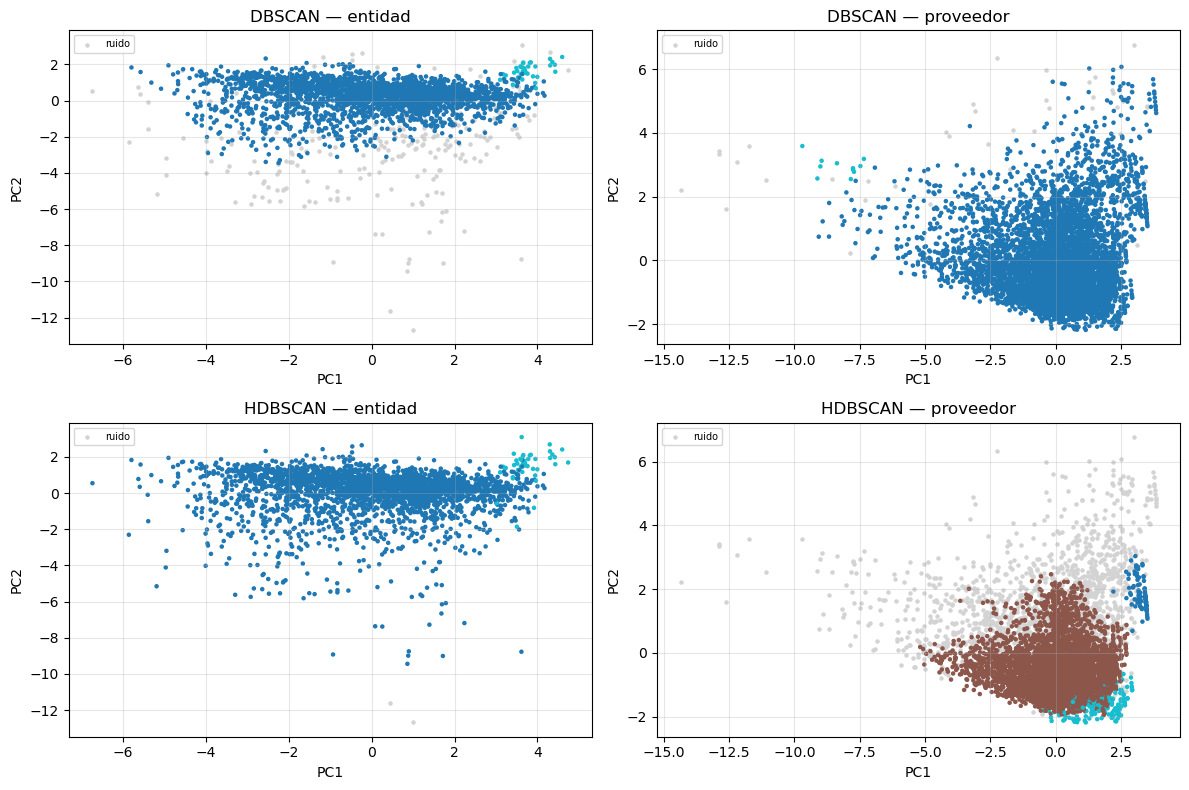

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for i, (s, (loc, X)) in enumerate(datos.items()):
    for j, metodo in enumerate(["dbscan", "hdbscan"]):
        if metodo not in resultados[s]:
            continue
        lab = resultados[s][metodo].to_numpy()
        ax[j, i].scatter(X[lab == -1, 0], X[lab == -1, 1], c="lightgrey", s=5, label="ruido")
        ax[j, i].scatter(X[lab >= 0, 0], X[lab >= 0, 1], c=lab[lab >= 0], cmap="tab10", s=5)
        ax[j, i].set_title(f"{metodo.upper()} — {s}"); ax[j, i].set_xlabel("PC1"); ax[j, i].set_ylabel("PC2"); ax[j, i].legend(fontsize=7)
mostrar_fig("densidad_pca")

#### Interpretación

- **ARI** (Adjusted Rand Index): 1 = mismas particiones, 0 = coincidencia al azar. Un ARI bajo entre KMeans y
  DBSCAN es esperable: KMeans fuerza grupos convexos de tamaño parecido y DBSCAN sigue la densidad
- Los **outliers** con su columna `rasgos` dicen *por qué* son atípicos (p. ej. `pct_directa ↑3.2σ, share_top ↑2.5σ`)
- **Encuadre ético:** un outlier es un actor que se aparta del patrón general. No implica irregularidad; muchas veces
  es una entidad con un mandato singular. Se presentan como **señales para revisión**, nunca como acusaciones

### 5. Escritura de resultados (incluye etiquetas por combinación para la web)

In [12]:
web = {}
for s, (loc, X) in datos.items():
    key = config[s]["key"]
    idx = np.random.RandomState(SEED).choice(len(loc), size=min(N_WEB, len(loc)), replace=False)
    w = loc.iloc[idx][[key, "nombre", "pc_0", "pc_1"]].copy()
    for (ss, ms, q), lab in etiquetas_db.items():
        if ss == s:
            w[f"db_{ms}_{int(q * 100)}"] = lab[idx]
    for (ss, mcs), (lab, _) in etiquetas_h.items():
        if ss == s:
            w[f"hdb_{mcs}"] = lab[idx]
    web[f"muestra_densidad_{s}"] = w

tablas = {"grid_dbscan": grid_db, "ari_densidad": ari, "outliers": outliers, **web}
if len(grid_h):
    tablas["grid_hdbscan"] = grid_h
escritos = {nombre: guardar_tabla(df, nombre) for nombre, df in tablas.items()}
print(f"Escrito en {SECCION}/temp/{NOTEBOOK}/: {', '.join(escritos)}")

Escrito en 02_Clustering/temp/c_densidad/: grid_dbscan, ari_densidad, outliers, muestra_densidad_entidad, muestra_densidad_proveedor, grid_hdbscan


#### a. Verificación

In [13]:
for nombre, n in escritos.items():
    leido = spark.read.parquet(str(tab_dir / nombre)).count()
    assert leido == n, f"{nombre}: esperaba {n}, leí {leido}"
    assert (web_dir / f"{nombre}.json").exists(), f"falta web/{nombre}.json"
figs = sorted(p.stem for p in fig_dir.glob("*.png"))
print(f"OK: {len(escritos)} tablas (parquet + json)" + (f" | {len(figs)} figuras: {', '.join(figs)}" if figs else ""))

OK: 6 tablas (parquet + json) | 2 figuras: densidad_pca, k_distancia


---
### 6. Cerrar sesión

In [14]:
spark.stop()